# Phân tích giá nhà Melbourne — Ridge vs Random Forest

**Bài toán chính:** dự đoán **giá bán của một căn nhà ở Melbourne (Úc) tại thời điểm giao dịch**,
dựa trên đặc điểm căn nhà + vị trí. Đây là bài toán **định giá (hedonic pricing)** — giá là hàm của
diện tích, số phòng, tuổi nhà, loại nhà, khoảng cách tới trung tâm và khu vực — **không phải dự báo
tương lai** (không có mốc thời gian cần dự báo trước), nên dữ liệu được chia ngẫu nhiên 80/20.

**Dữ liệu:** Kaggle [dansbecker/melbourne-housing-snapshot](https://www.kaggle.com/datasets/dansbecker/melbourne-housing-snapshot),
file `melb_data.csv` — 13.580 giao dịch Melbourne 2016–2017, 21 cột, đơn vị tiền AUD.
Target chính là **log(giá)**, kết quả cuối quy về AUD để đọc.

**Cách chạy notebook này:** up file `melb_data.csv` vào cùng thư mục với notebook (hoặc sửa `DATA_DIR`
ở cell dưới). Mọi cell chạy được từ đầu tới cuối, `random_state=42` ở mọi chỗ ngẫu nhiên.
Môi trường gốc: Python 3.12, scikit-learn 1.9.1, pandas 3.1.1, numpy 2.5.5, matplotlib, scipy.

In [1]:
import json
import time
import warnings
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib
import matplotlib.pyplot as plt
from scipy import stats
from sklearn.base import BaseEstimator, TransformerMixin
from sklearn.compose import ColumnTransformer
from sklearn.ensemble import RandomForestRegressor
from sklearn.impute import SimpleImputer
from sklearn.inspection import permutation_importance
from sklearn.linear_model import RidgeCV
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score
from sklearn.model_selection import KFold, cross_val_score, learning_curve, train_test_split
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import OneHotEncoder, StandardScaler

warnings.filterwarnings("ignore")
plt.rcParams.update({"font.size": 11, "axes.edgecolor": "#333333",
                     "axes.labelcolor": "#101216", "text.color": "#101216",
                     "xtick.color": "#101216", "ytick.color": "#101216",
                     "figure.facecolor": "white", "axes.facecolor": "white"})
C_RIDGE, C_RF = "#1f77b4", "#2ca02c"
RANDOM_STATE = 42

# --- đường dẫn dữ liệu: ưu tiên file cạnh notebook, fallback về thư mục gốc ---
DATA_DIR = Path(".")
CSV_PATH = DATA_DIR / "melb_data.csv"
if not CSV_PATH.exists():
    CSV_PATH = Path("/home/hatch/workspace/melbourne/melb_data.csv")
print("CSV:", CSV_PATH, "| tồn tại:", CSV_PATH.exists())

CSV: melb_data.csv | tồn tại: True


## 1. Tổng quan dữ liệu

Đọc file và xem hình dạng tổng thể trước: bao nhiêu dòng, bao nhiêu cột, kiểu dữ liệu, có dòng trùng không.

In [2]:
df = pd.read_csv(CSV_PATH)
print("Shape (dòng, cột):", df.shape)
print()
print(df.dtypes.to_string())
print()
print("Số dòng trùng hoàn toàn:", df.duplicated().sum())
print("Số dòng trùng (Suburb, Address, Date, Price):",
      df.duplicated(subset=["Suburb", "Address", "Date", "Price"]).sum())
print("Khoảng ngày giao dịch:", df["Date"].min(), "->", df["Date"].max(),
      "| số ngày khác nhau:", df["Date"].nunique())
print("Price thiếu:", df["Price"].isna().sum(), "| Price == 0:", (df["Price"] == 0).sum())
df.head()

Shape (dòng, cột): (13580, 21)

Suburb               str
Address              str
Rooms              int64
Type                 str
Price            float64
Method               str
SellerG              str
Date                 str
Distance         float64
Postcode         float64
Bedroom2         float64
Bathroom         float64
Car              float64
Landsize         float64
BuildingArea     float64
YearBuilt        float64
CouncilArea          str
Lattitude        float64
Longtitude       float64
Regionname           str
Propertycount    float64



Số dòng trùng hoàn toàn:

 0
Số dòng trùng (Suburb, Address, Date, Price): 1
Khoảng ngày giao dịch: 1/07/2017 -> 9/09/2017 | số ngày khác nhau: 58
Price thiếu: 0 | Price == 0: 0


,Suburb,Address,Rooms,Type,Price,Method,SellerG,Date,Distance,Postcode,...,Bathroom,Car,Landsize,BuildingArea,YearBuilt,CouncilArea,Lattitude,Longtitude,Regionname,Propertycount
0,Abbotsford,85 Turner St,2,h,1480000.0,S,Biggin,3/12/2016,2.5,3067.0,...,1.0,1.0,202.0,NaN,NaN,Yarra,-37.7996,144.9984,Northern Metropolitan,4019.0
1,Abbotsford,25 Bloomburg St,2,h,1035000.0,S,Biggin,4/02/2016,2.5,3067.0,...,1.0,0.0,156.0,79.0,1900.0,Yarra,-37.8079,144.9934,Northern Metropolitan,4019.0
2,Abbotsford,5 Charles St,3,h,1465000.0,SP,Biggin,4/03/2017,2.5,3067.0,...,2.0,0.0,134.0,150.0,1900.0,Yarra,-37.8093,144.9944,Northern Metropolitan,4019.0
3,Abbotsford,40 Federation La,3,h,850000.0,PI,Biggin,4/03/2017,2.5,3067.0,...,2.0,1.0,94.0,NaN,NaN,Yarra,-37.7969,144.9969,Northern Metropolitan,4019.0
4,Abbotsford,55a Park St,4,h,1600000.0,VB,Nelson,4/06/2016,2.5,3067.0,...,1.0,2.0,120.0,142.0,2014.0,Yarra,-37.8072,144.9941,Northern Metropolitan,4019.0


**Đọc gì từ output trên:** 13.580 dòng × 21 cột, không có dòng trùng hoàn toàn, chỉ 1 dòng trùng
theo (Suburb, Address, Date, Price) — gần như không có trùng lặp. Target `Price` không thiếu dòng nào,
nên không mất mẫu vì thiếu target. Các cột gồm: `Suburb, Address, Rooms, Type, Price, Method, SellerG,
Date, Distance, Postcode, Bedroom2, Bathroom, Car, Landsize, BuildingArea, YearBuilt, CouncilArea,
Lattitude, Longtitude, Regionname, Propertycount`.

## 2. Khám phá dữ liệu (EDA)

### 2.1 Dữ liệu thiếu — bộ bẩn nhất trong 4 bộ đã chạy

BuildingArea    47.5
YearBuilt       39.6
CouncilArea     10.1
Car              0.5



Số dòng dính thiếu (ít nhất 1 cột): 7384 / 13580


Số dòng đủ cả 3 cột Landsize / BuildingArea / YearBuilt: 6858


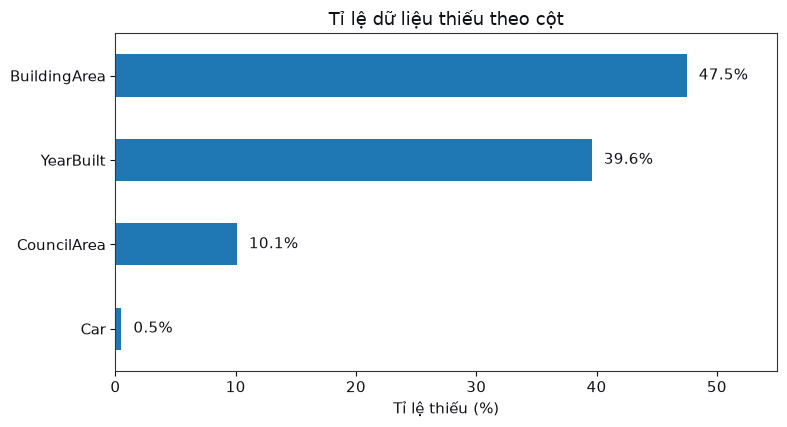

In [3]:
miss = df.isna().sum()
miss_pct = (miss / len(df) * 100).round(1)
print(miss_pct[miss_pct > 0].sort_values(ascending=False).to_string())
print("\nSố dòng dính thiếu (ít nhất 1 cột):", df.isna().any(axis=1).sum(), "/", len(df))
print("Số dòng đủ cả 3 cột Landsize / BuildingArea / YearBuilt:",
      df[["Landsize", "BuildingArea", "YearBuilt"]].notna().all(axis=1).sum())

m = miss_pct[miss_pct > 0].sort_values()
fig, ax = plt.subplots(figsize=(8, 4.4))
m.plot.barh(ax=ax, color=C_RIDGE)
ax.set_xlabel("Tỉ lệ thiếu (%)")
ax.set_title("Tỉ lệ dữ liệu thiếu theo cột")
for i, v in enumerate(m.values):
    ax.text(v + 1, i, f"{v:.1f}%", va="center")
ax.set_xlim(0, 55)
plt.tight_layout()
plt.show()

**Đọc biểu đồ:** thiếu nặng nhất ở `BuildingArea` 47,5% (6.450 dòng) và `YearBuilt` 39,6%
(5.375 dòng), rồi `CouncilArea` 10,1% và `Car` 0,5%. Tổng cộng 7.384/13.580 dòng dính thiếu, chỉ 6.858
dòng đủ cả 3 cột số quan trọng. Hệ quả trực tiếp cho tiền xử lý (mục 3): **không thể xóa dòng thiếu** —
xóa sẽ mất 54% dữ liệu — nên phải điền giá trị (impute) và giữ lại 2 cờ thiếu để mô hình biết dòng nào
thiếu hồ sơ.

### 2.2 Phân bố giá — vì sao phải lấy log

count      13580.0
mean     1075684.1
std       639310.7
min        85000.0
1%        300000.0
5%        405000.0
25%       650000.0
50%       903000.0
75%      1330000.0
95%      2290050.0
99%      3338150.0
max      9000000.0

Price skew: 2.24 | log(Price) skew: 0.18
Landsize skew: 95.24 | log(Landsize) skew: 0.01
BuildingArea skew: 77.69 | log(BuildingArea) skew: -1.81


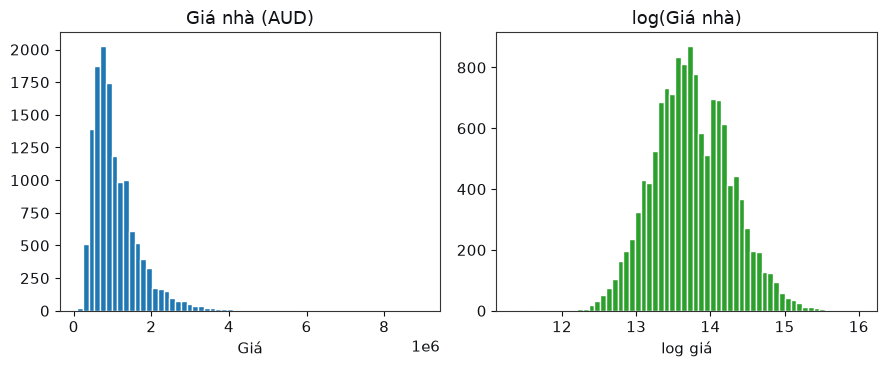

In [4]:
print(df["Price"].describe(percentiles=[.01, .05, .25, .5, .75, .95, .99]).round(1).to_string())
print("\nPrice skew:", round(df["Price"].skew(), 2),
      "| log(Price) skew:", round(np.log(df["Price"]).skew(), 2))
print("Landsize skew:", round(df["Landsize"].skew(), 2),
      "| log(Landsize) skew:", round(np.log(df["Landsize"].replace(0, np.nan)).skew(), 2))
print("BuildingArea skew:", round(df["BuildingArea"].skew(), 2),
      "| log(BuildingArea) skew:", round(np.log(df["BuildingArea"].replace(0, np.nan)).skew(), 2))

df["y_log"] = np.log(df["Price"])
fig, ax = plt.subplots(1, 2, figsize=(9, 3.8))
ax[0].hist(df["Price"], bins=60, color=C_RIDGE, edgecolor="white")
ax[0].set_title("Giá nhà (AUD)")
ax[0].set_xlabel("Giá")
ax[1].hist(df["y_log"], bins=60, color=C_RF, edgecolor="white")
ax[1].set_title("log(Giá nhà)")
ax[1].set_xlabel("log giá")
plt.tight_layout()
plt.show()

**Đọc biểu đồ:** giá lệch phải rất mạnh — trung bình 1.075.684 AUD, trung vị 903.000, min 85.000,
max 9.000.000 (gấp 10 lần trung vị), skew 2,24. Sau khi lấy log, phân bố gần đối xứng (skew 0,18),
đuôi phải được kéo về. Vì vậy **target của mô hình là log(Price)**, kết quả cuối quy về AUD để đọc.
Cùng lý do, `Landsize` (skew 95,24) và `BuildingArea` (skew 77,69) cũng phải lấy log trước khi đưa
vào Ridge.

### 2.3 Tương quan — biến nào đi cùng giá?

Tương quan với Price (xếp theo |r|):
Rooms            0.497
Bedroom2         0.476
Bathroom         0.467
YearBuilt       -0.324
Car              0.239
Distance        -0.163
BuildingArea     0.091
Propertycount   -0.042
Landsize         0.038

Rooms - Bedroom2 corr: 0.944


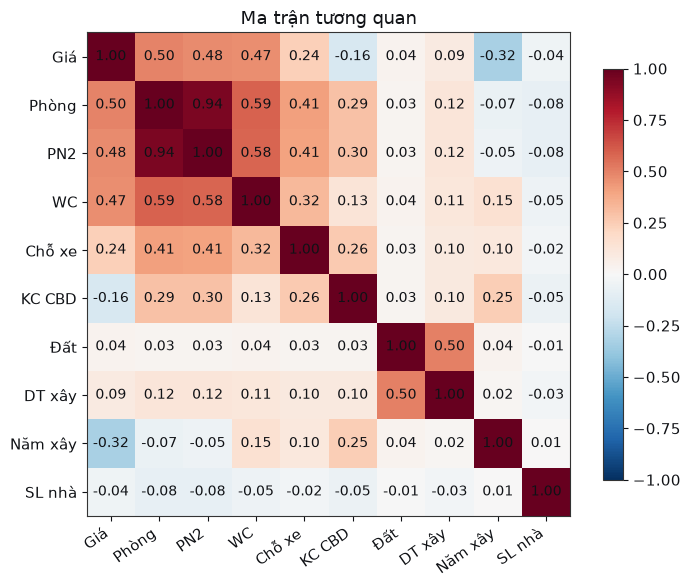

In [5]:
cols = ["Price", "Rooms", "Bedroom2", "Bathroom", "Car", "Distance",
        "Landsize", "BuildingArea", "YearBuilt", "Propertycount"]
print("Tương quan với Price (xếp theo |r|):")
print(df[cols].corr()["Price"].drop("Price").round(3)
      .sort_values(key=abs, ascending=False).to_string())
print("\nRooms - Bedroom2 corr:",
      round(df["Rooms"].corr(df["Bedroom2"]), 3))

corr = df[cols].corr()
labels = ["Giá", "Phòng", "PN2", "WC", "Chỗ xe", "KC CBD", "Đất", "DT xây", "Năm xây", "SL nhà"]
fig, ax = plt.subplots(figsize=(7.5, 6))
im = ax.imshow(corr.values, cmap="RdBu_r", vmin=-1, vmax=1)
ax.set_xticks(range(len(labels)))
ax.set_yticks(range(len(labels)))
ax.set_xticklabels(labels, rotation=35, ha="right")
ax.set_yticklabels(labels)
for i in range(len(labels)):
    for j in range(len(labels)):
        ax.text(j, i, f"{corr.values[i, j]:.2f}", ha="center", va="center", fontsize=10)
ax.set_title("Ma trận tương quan")
plt.colorbar(im, ax=ax, shrink=0.85)
plt.tight_layout()
plt.show()

**Đọc biểu đồ:** tương quan mạnh nhất với giá là `Rooms` 0,497, `Bedroom2` 0,476 và `Bathroom`
0,467; `YearBuilt` −0,324 (nhà mới hơn thì đắt hơn). Ngược lại, `Landsize` chỉ 0,038 và `BuildingArea`
chỉ 0,091 — thấp bất thường, vì cả hai đều bẩn (thiếu nặng + giá trị 0 + outlier cực đoan), chưa phải vì
diện tích không quan trọng. **Bẫy cần tránh:** `Rooms` và `Bedroom2` tương quan 0,94 — gần như cùng một
thông tin — nên chỉ giữ `Rooms`, bỏ `Bedroom2` để tránh đa cộng tuyến thừa.

### 2.4 Khoảng cách tới trung tâm vs giá

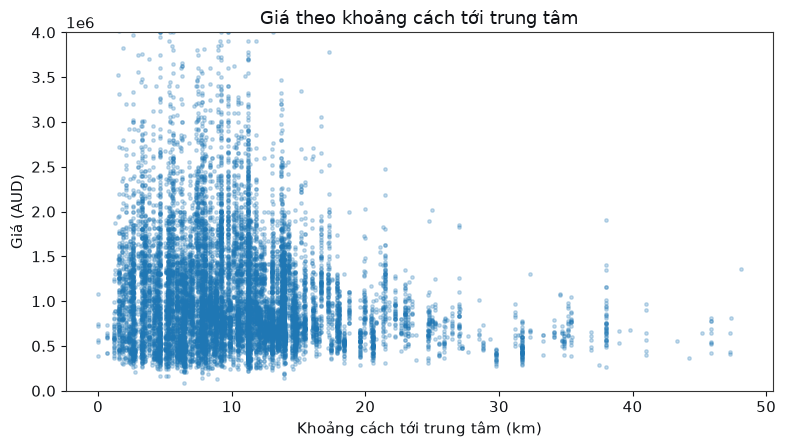

Tương quan Distance - Price: -0.163
               mean     median  count
Distance                             
(0, 5]    1133805.0  1000000.0   2231
(5, 10]   1160786.0   970000.0   5097
(10, 20]  1018714.0   863000.0   5515
(20, 50]   738044.0   690000.0    731


In [6]:
fig, ax = plt.subplots(figsize=(8, 4.6))
ax.scatter(df["Distance"], df["Price"], s=6, alpha=0.25, color=C_RIDGE)
ax.set_xlabel("Khoảng cách tới trung tâm (km)")
ax.set_ylabel("Giá (AUD)")
ax.set_title("Giá theo khoảng cách tới trung tâm")
ax.set_ylim(0, 4_000_000)
plt.tight_layout()
plt.show()
print("Tương quan Distance - Price:",
      round(df["Distance"].corr(df["Price"]), 3))
print(df.groupby(pd.cut(df["Distance"], [0, 5, 10, 20, 50]))["Price"]
      .agg(["mean", "median", "count"]).round(0).to_string())

**Đọc biểu đồ:** giá giảm rõ khi xa trung tâm — nhà trong 5 km đắt gấp đôi nhà ngoài 20 km
(xem bảng trung bình theo nhóm khoảng cách ở output trên). Đây là tín hiệu vị trí quan trọng thứ hai
sau khu vực, và là một trong những biến Random Forest dùng nhiều nhất (permutation importance 0,206,
mục 5).

### 2.5 Giá theo vùng (Regionname) và loại nhà (Type)

Giá trung bình theo Regionname:
                                 mean     median  count
Regionname                                             
Eastern Metropolitan        1104080.0  1010000.0   1471
Eastern Victoria             699981.0   670000.0     53
Northern Metropolitan        898171.0   806250.0   3890
Northern Victoria            594829.0   540000.0     41
South-Eastern Metropolitan   922944.0   850000.0    450
Southern Metropolitan       1372963.0  1250000.0   4695
Western Metropolitan         866421.0   793000.0   2948
Western Victoria             397523.0   400000.0     32

Giá trung bình theo Type (h = nhà riêng, u = căn hộ, t = townhouse):


           mean     median  count
Type                             
h     1242665.0  1080000.0   9449
t      933735.0   846750.0   1114
u      605127.0   560000.0   3017


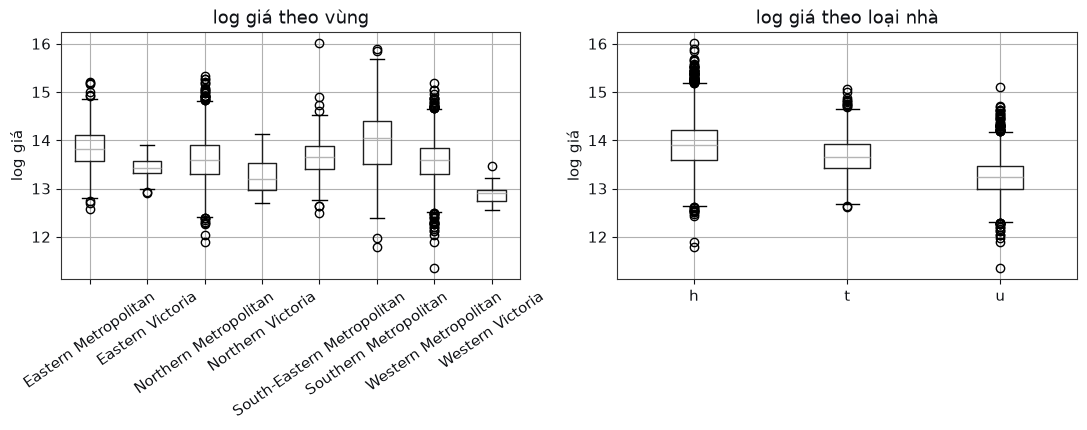

In [7]:
print("Giá trung bình theo Regionname:")
print(df.groupby("Regionname")["Price"].agg(["mean", "median", "count"]).round(0).to_string())
print("\nGiá trung bình theo Type (h = nhà riêng, u = căn hộ, t = townhouse):")
print(df.groupby("Type")["Price"].agg(["mean", "median", "count"]).round(0).to_string())

fig, ax = plt.subplots(1, 2, figsize=(11, 4.6))
df.boxplot(column="y_log", by="Regionname", ax=ax[0])
ax[0].set_title("log giá theo vùng")
ax[0].set_xlabel("")
ax[0].set_ylabel("log giá")
ax[0].tick_params(axis="x", rotation=35)
df.boxplot(column="y_log", by="Type", ax=ax[1])
ax[1].set_title("log giá theo loại nhà")
ax[1].set_xlabel("")
ax[1].set_ylabel("log giá")
plt.suptitle("")
plt.tight_layout()
plt.show()

**Đọc biểu đồ:** Southern Metropolitan đắt nhất (trung bình 1.372.963 AUD), Western Victoria
rẻ nhất (397.523 AUD) — chênh nhau hơn 3 lần chỉ vì vị trí. Nhà riêng (h) đắt hơn căn hộ (u) rõ rệt.
Boxplot dùng log giá để đuôi dài 9 triệu AUD không bóp dẹp phần còn lại. Kết luận: **giá chạy theo vị
trí trước tiên**, rồi mới tới đặc điểm căn nhà — đây là lý do Random Forest thắng Ridge ở bộ này
(xem mục 4).

### 2.6 Outlier — giá trị 0 và đuôi cực đoan

In [8]:
print("Outlier theo IQR (1.5 × IQR):")
for c in ["Price", "Rooms", "Bathroom", "Car", "Distance", "Landsize",
          "BuildingArea", "YearBuilt", "Propertycount"]:
    s = df[c].dropna()
    q1, q3 = s.quantile(.25), s.quantile(.75)
    iqr = q3 - q1
    n = ((s < q1 - 1.5 * iqr) | (s > q3 + 1.5 * iqr)).sum()
    print(f"{c:14s} outlier={n:5d} ({100 * n / len(s):5.1f}%)  "
          f"min={s.min():.1f}  max={s.max():.1f}  p99={s.quantile(.99):.1f}")
print("\nLandsize == 0:", (df["Landsize"] == 0).sum(), "dòng | BuildingArea == 0:",
      (df["BuildingArea"] == 0).sum(), "dòng")
print("YearBuilt < 1800:", (df["YearBuilt"] < 1800).sum(), "dòng | YearBuilt > 2017:",
      (df["YearBuilt"] > 2017).sum(), "dòng (có 1 dòng ghi năm 1196 và 1 dòng 2018)")

Outlier theo IQR (1.5 × IQR):
Price          outlier=  612 (  4.5%)  min=85000.0  max=9000000.0  p99=3338150.0
Rooms          outlier=  682 (  5.0%)  min=1.0  max=10.0  p99=5.0
Bathroom       outlier=  143 (  1.1%)  min=0.0  max=8.0  p99=4.0
Car            outlier=  644 (  4.8%)  min=0.0  max=10.0  p99=5.0
Distance       outlier=  411 (  3.0%)  min=0.0  max=48.1  p99=32.3
Landsize       outlier=  368 (  2.7%)  min=0.0  max=433014.0  p99=2959.8
BuildingArea   outlier=  353 (  5.0%)  min=0.0  max=44515.0  p99=466.4
YearBuilt      outlier=    6 (  0.1%)  min=1196.0  max=2018.0  p99=2015.0
Propertycount  outlier=  359 (  2.6%)  min=249.0  max=21650.0  p99=21650.0

Landsize == 0: 1939 dòng | BuildingArea == 0: 17 dòng
YearBuilt < 1800: 1 dòng | YearBuilt > 2017: 1 dòng (có 1 dòng ghi năm 1196 và 1 dòng 2018)


**Đọc output:** `Landsize` max 433.014 m² trong khi p99 chỉ 2.960 — đuôi cực đoan; có 1.939
giá trị 0 (đất 0 m² là dữ liệu lỗi, không phải nhà không có đất). `BuildingArea` max 44.515 trong khi
p99 là 466. `YearBuilt` có 1 dòng ghi năm 1196. Cách xử lý (mục 3): **coi 0 là thiếu rồi mới log,
winsorise 1%/99% để chặn đuôi** — chặn thay vì xóa dòng, vì xóa sẽ mất mẫu trên bộ đã thiếu nặng.

### 2.7 Biến phân loại — 314 suburb là vấn đề lớn nhất

In [9]:
print("Suburb:", df["Suburb"].nunique(), "giá trị khác nhau")
print("Suburb có <10 dòng:", (df["Suburb"].value_counts() < 10).sum(), "suburb")
print("Top 10 suburb nhiều giao dịch nhất:")
print(df["Suburb"].value_counts().head(10).to_string())
print("\nType (h/u/t):")
print(df["Type"].value_counts(dropna=False).to_string())
print("\nMethod:")
print(df["Method"].value_counts(dropna=False).to_string())
print("\nRegionname: 8 vùng")
print(df["Regionname"].value_counts(dropna=False).to_string())
print("\nSellerG:", df["SellerG"].nunique(), "hãng môi giới khác nhau")
print("Postcode:", df["Postcode"].nunique(), "mã khác nhau")

Suburb: 314 giá trị khác nhau
Suburb có <10 dòng: 102 suburb
Top 10 suburb nhiều giao dịch nhất:


Suburb
Reservoir         359
Richmond          260
Bentleigh East    249
Preston           239
Brunswick         222
Essendon          220
South Yarra       202
Glen Iris         195
Hawthorn          191
Coburg            190

Type (h/u/t):
Type
h    9449
u    3017
t    1114

Method:
Method
S     9022
SP    1703
PI    1564
VB    1199
SA      92

Regionname: 8 vùng
Regionname
Southern Metropolitan         4695
Northern Metropolitan         3890
Western Metropolitan          2948
Eastern Metropolitan          1471
South-Eastern Metropolitan     450
Eastern Victoria                53
Northern Victoria               41
Western Victoria                32

SellerG: 268 hãng môi giới khác nhau
Postcode: 198 mã khác nhau


**Đọc output:** `Suburb` có 314 giá trị, trong đó 102 suburb có dưới 10 dòng — OneHot hết sẽ ra
314 cột, phần lớn thưa thớt vô dụng. Cách xử lý (mục 3, bước 6): chỉ giữ 114 suburb có ≥30 dòng trong
train, còn lại gộp thành `"Other"`. Ngược lại, `SellerG` có 268 hãng môi giới — không phải đặc tính của
ngôi nhà nên bỏ; `Postcode` (198 mã) trùng thông tin với `Suburb` nên bỏ.

## 3. Tiền xử lý — 10 bước, mỗi bước đều có lý do

1. **Bỏ `Address`** (định danh từng nhà), **`SellerG`** (268 hãng môi giới, không phải đặc tính nhà),
   **`Postcode`** (trùng `Suburb`), **`Date`** (định giá tại thời điểm giao dịch, không dự báo tương lai),
   **`Bedroom2`** (trùng `Rooms`, corr 0,94 — giữ `Rooms`).
2. **Target `log(Price)`:** giá lệch phải mạnh (skew 2,24, max gấp 10 lần trung vị) nên log kéo đuôi về;
   kết quả cuối quy về AUD để đọc.
3. **`Landsize`/`BuildingArea` = 0 coi như THIẾU rồi mới lấy log:** đất 0 m² là dữ liệu lỗi, không phải
   nhà không có đất; log(0) không tính được nên phải xử lý trước.
4. **Log `Landsize`/`BuildingArea`:** cả hai lệch cực mạnh (skew 95 và 78) nên log là bắt buộc trước khi
   đưa vào Ridge.
5. **Feature mới:** `Age = 2017 − YearBuilt` (tuổi nhà dễ đọc hơn năm xây); 2 cờ thiếu
   `BuildingArea_missing`, `YearBuilt_missing` (việc thiếu diện tích/năm xây tự nó cũng mang thông tin).
6. **Suburb gộp:** giữ 114 suburb có ≥30 dòng trong TRAIN (chiếm 82,8% dòng train), còn lại gộp thành
   `"Other"` — danh sách học từ TRAIN để không rò rỉ test. 314 suburb mà OneHot hết sẽ ra 314 cột,
   phần lớn thưa thớt vô dụng.
7. **Median/mode impute học từ TRAIN** (thiếu quá nặng để xóa dòng — xóa sẽ mất 54% dữ liệu).
8. **Winsorise 1%/99% theo train:** chặn đuôi cực đoan (`Landsize` 433.014, `BuildingArea` 44.515,
   `YearBuilt` 1196) thay vì xóa dòng.
9. **OneHot** cho `Type, Method, Regionname, CouncilArea, Suburb_grouped`. **StandardScaler cho Ridge**
   (Ridge phạt hệ số nên cần cùng thang đo); Random Forest không cần scaler.
10. **Chia ngẫu nhiên 80/20, `random_state=42`:** train 10.864 / test 2.716. Mọi tham số tiền xử lý
    chỉ học từ TRAIN — đây là luật chống rò rỉ quan trọng nhất của cả notebook.

In [10]:
# --- Bước 2-5: target log + log diện tích (0 -> thiếu) + Age + cờ thiếu ---
df["log_Landsize"] = np.log(df["Landsize"].replace(0, np.nan))
df["log_BuildingArea"] = np.log(df["BuildingArea"].replace(0, np.nan))
df["Age"] = 2017 - df["YearBuilt"]
df["BuildingArea_missing"] = df["BuildingArea"].isna().astype(int)
df["YearBuilt_missing"] = df["YearBuilt"].isna().astype(int)
df["y"] = np.log(df["Price"])

NUM = ["Rooms", "Bathroom", "Car", "Distance", "log_Landsize", "log_BuildingArea",
       "Age", "Lattitude", "Longtitude", "Propertycount",
       "BuildingArea_missing", "YearBuilt_missing"]
CAT = ["Type", "Method", "Regionname", "CouncilArea", "Suburb_grouped"]
FEATS = NUM + CAT

X = df[NUM + ["Suburb"] + ["Type", "Method", "Regionname", "CouncilArea"]]
y = df["y"]
y_raw = df["Price"]
X_tr, X_te, y_tr, y_te, yraw_tr, yraw_te = train_test_split(
    X, y, y_raw, test_size=0.2, random_state=RANDOM_STATE)
print(f"train {len(X_tr)} | test {len(X_te)}")

# --- Bước 6: gộp suburb, danh sách học từ TRAIN only ---
vc = X_tr["Suburb"].value_counts()
keep_suburbs = set(vc[vc >= 30].index)
print(f"suburb giữ (>=30 dòng train): {len(keep_suburbs)} / {X_tr['Suburb'].nunique()} "
      f"-> bao phủ {(X_tr['Suburb'].isin(keep_suburbs)).mean() * 100:.1f}% dòng train")


def add_suburb_group(Xdf):
    Xdf = Xdf.copy()
    Xdf["Suburb_grouped"] = np.where(Xdf["Suburb"].isin(keep_suburbs), Xdf["Suburb"], "Other")
    return Xdf[FEATS]


X_tr = add_suburb_group(X_tr)
X_te = add_suburb_group(X_te)
X_tr.head(3)

train 10864 | test 2716
suburb giữ (>=30 dòng train): 114 / 306 -> bao phủ 82.8% dòng train


,Rooms,Bathroom,Car,Distance,log_Landsize,log_BuildingArea,Age,Lattitude,Longtitude,Propertycount,BuildingArea_missing,YearBuilt_missing,Type,Method,Regionname,CouncilArea,Suburb_grouped
12796,4,2.0,2.0,14.2,6.543912,5.075174,47.0,-37.86127,145.14271,13366.0,0,0,h,S,Eastern Metropolitan,NaN,Mount Waverley
9642,3,1.0,2.0,14.2,6.697034,NaN,NaN,-37.86838,145.14664,13366.0,1,1,h,S,Eastern Metropolitan,Monash,Mount Waverley
3207,2,1.0,1.0,4.6,4.406719,NaN,NaN,-37.81800,145.02680,11308.0,1,1,u,S,Southern Metropolitan,Boroondara,Hawthorn


**Hai bước đáng chú ý nhất:**

- **Bước 3 (0 → thiếu):** `log(0)` không tính được, mà 0 ở đây là lỗi nhập liệu (đất 0 m²). Coi 0 là
  thiếu rồi điền trung vị thì nhà đó vẫn giữ được các thông tin khác (phòng, vị trí...) thay vì bị xóa.
- **Bước 6 (gộp suburb):** danh sách 114 suburb được học **từ train only**. Nếu học từ toàn bộ dữ liệu
  (kể cả test) thì test đã "rò" vào bước tiền xử lý — R² test sẽ phồng lên giả. Cùng luật đó, median,
  mode và ngưỡng winsorise ở bước 7–8 cũng chỉ học từ train.

In [11]:
# --- Bước 7-9: impute + winsorise (ngưỡng từ TRAIN) + OneHot + scaler ---
# Ngưỡng winsorise 1%/99% học từ TRAIN
lo = X_tr[NUM].quantile(0.01).to_numpy()
hi = X_tr[NUM].quantile(0.99).to_numpy()


class Winsoriser(BaseEstimator, TransformerMixin):
    """Chặn giá trị số vào khoảng [lo, hi] học từ train (chặn đuôi, không xóa dòng)."""

    def fit(self, X, y=None):
        self.n_features_in_ = np.asarray(X).shape[1]
        return self

    def transform(self, X):
        X = np.asarray(X, dtype=float).copy()
        return np.clip(X, lo, hi)


def prep(scaler):
    num_pipe = make_pipeline(SimpleImputer(strategy="median"), Winsoriser(), scaler) \
        if scaler else make_pipeline(SimpleImputer(strategy="median"), Winsoriser())
    cat_pipe = make_pipeline(SimpleImputer(strategy="most_frequent"),
                             OneHotEncoder(handle_unknown="ignore"))
    return ColumnTransformer([("num", num_pipe, NUM), ("cat", cat_pipe, CAT)])


ridge_pipe = make_pipeline(prep(StandardScaler()),
                           RidgeCV(alphas=[0.1, 1, 10, 100, 1000], cv=5))
rf_pipe = make_pipeline(prep(None),
                        RandomForestRegressor(n_estimators=300, min_samples_leaf=2,
                                              n_jobs=-1, random_state=RANDOM_STATE))

# Xem ma trận sau tiền xử lý có bao nhiêu cột
Xtr_enc = prep(StandardScaler()).fit_transform(X_tr, y_tr)
print("Sau tiền xử lý: train", Xtr_enc.shape, "| test", prep(StandardScaler()).fit(X_tr, y_tr).transform(X_te).shape)
print(f"Số cột OneHot (Type 3 + Method 5 + Regionname 8 + CouncilArea ~30 + Suburb 115): "
      f"{Xtr_enc.shape[1] - len(NUM)} cột phân loại + {len(NUM)} cột số")

Sau tiền xử lý: train (10864, 176) | test (2716, 176)
Số cột OneHot (Type 3 + Method 5 + Regionname 8 + CouncilArea ~30 + Suburb 115): 164 cột phân loại + 12 cột số


## 4. Lý thuyết ngắn: Ridge vs Random Forest — và vì sao áp dụng vào bài này

**Ridge Regression** — hồi quy tuyến tính + phạt L2: hàm mất mát = sai số bình phương + α × (tổng bình
phương hệ số). Phạt α kéo các hệ số nhỏ lại, chống đa cộng tuyến (ở đây `Rooms`/`Bathroom`/`log_Landsize`
tương quan nhau) và chống overfitting. Ưu điểm: đọc được hệ số từng biến (suburb nào cộng bao nhiêu),
ổn định, nhanh. Yếu điểm: chỉ vẽ được **đường thẳng** — quan hệ phi tuyến (vị trí × loại nhà × khoảng
cách tương tác nhau) thì nó không bắt được. α chọn bằng kiểm chứng chéo 5-fold trong train
(`RidgeCV`, lưới [0,1; 1; 10; 100; 1000]).

**Random Forest Regression** — trung bình 300 cây quyết định, mỗi cây học trên một mẫu bootstrap và
chỉ xem một tập con feature ở mỗi lần chia. Ưu điểm: bắt được tương tác phi tuyến và ngưỡng (ví dụ:
giá tăng mạnh khi `Distance` < 5 km rồi chững lại) mà không cần mình tự tạo feature tương tác. Yếu
điểm: khó giải thích từng hệ số, dễ overfit (cây sâu nhớ được train), không ngoại suy ngoài khoảng
giá đã thấy trong train. `min_samples_leaf=2` chặn cây chia tới từng dòng lẻ.

**Áp vào bài này:** giá Melbourne chạy theo vị trí theo cách phi tuyến (khu vực × loại nhà × khoảng
cách), nên cây có lợi thế; ở bộ nhà Ấn Độ thì quan hệ gần tuyến tính sau log nên Ridge thắng. Cùng một
cặp mô hình, bộ nào thắng phụ thuộc tín hiệu trong dữ liệu, không phụ thuộc thuật toán.

## 5. Huấn luyện và đánh giá trên test

Đánh giá trên cả hai thang: **R² trên log giá** (thang mô hình học) và **R² quy về giá thật AUD**
(thang người đọc hiểu), kèm MAE và sai số % trung vị (MedAPE). Baseline đoán trung bình train cho
mọi nhà — mô hình nào cũng phải thắng nó mới có nghĩa.

In [12]:
def metrics(name, y_true_log, pred_log, y_true_raw, secs=None):
    usd_pred = np.exp(pred_log)
    m = {
        "R2_log": round(float(r2_score(y_true_log, pred_log)), 4),
        "R2_raw": round(float(r2_score(y_true_raw, usd_pred)), 4),
        "MAE_log": round(float(mean_absolute_error(y_true_log, pred_log)), 4),
        "MAE_raw": round(float(mean_absolute_error(y_true_raw, usd_pred)), 1),
        "RMSE_raw": round(float(mean_squared_error(y_true_raw, usd_pred) ** 0.5), 1),
        "MedAPE_pct": round(float(np.median(np.abs(usd_pred / y_true_raw - 1)) * 100), 2),
    }
    if secs is not None:
        m["train_sec"] = round(secs, 1)
    print(name, m)
    return m


results = {}
pred_mean = np.full(len(X_te), y_tr.mean())
results["Mean baseline"] = metrics("Mean baseline", y_te, pred_mean, yraw_te)

t = time.time()
ridge_pipe.fit(X_tr, y_tr)
alpha = ridge_pipe[-1].alpha_
pred_ridge = ridge_pipe.predict(X_te)
results["Ridge"] = metrics("Ridge", y_te, pred_ridge, yraw_te, time.time() - t)
results["Ridge"]["alpha"] = float(alpha)
results["Ridge"]["R2_train_log"] = round(float(r2_score(y_tr, ridge_pipe.predict(X_tr))), 4)
print("Ridge alpha được chọn:", alpha)

t = time.time()
rf_pipe.fit(X_tr, y_tr)
pred_rf = rf_pipe.predict(X_te)
results["RandomForest"] = metrics("RandomForest", y_te, pred_rf, yraw_te, time.time() - t)
results["RandomForest"]["R2_train_log"] = round(float(r2_score(y_tr, rf_pipe.predict(X_tr))), 4)

print("\nVí dụ 1 dòng test: thực tế / Ridge / RF (AUD):",
      round(float(yraw_te.iloc[0]), 0),
      round(float(np.exp(pred_ridge[0])), 0),
      round(float(np.exp(pred_rf[0])), 0))

pd.DataFrame(results).T

Mean baseline {'R2_log': -0.0001, 'R2_raw': -0.0547, 'MAE_log': 0.4204, 'MAE_raw': 440154.0, 'RMSE_raw': 647264.3, 'MedAPE_pct': 34.66}


Ridge {'R2_log': 0.7936, 'R2_raw': 0.7583, 'MAE_log': 0.1831, 'MAE_raw': 198758.7, 'RMSE_raw': 309873.5, 'MedAPE_pct': 14.83, 'train_sec': 5.5}
Ridge alpha được chọn: 1.0


RandomForest {'R2_log': 0.8685, 'R2_raw': 0.8175, 'MAE_log': 0.1383, 'MAE_raw': 158609.5, 'RMSE_raw': 269213.2, 'MedAPE_pct': 10.39, 'train_sec': 184.1}



Ví dụ 1 dòng test: thực tế / Ridge / RF (AUD): 2600000.0 2175376.0 2176653.0


,R2_log,R2_raw,MAE_log,MAE_raw,RMSE_raw,MedAPE_pct,train_sec,alpha,R2_train_log
Mean baseline,-0.0001,-0.0547,0.4204,440154.0,647264.3,34.66,NaN,NaN,NaN
Ridge,0.7936,0.7583,0.1831,198758.7,309873.5,14.83,5.5,1.0,0.7955
RandomForest,0.8685,0.8175,0.1383,158609.5,269213.2,10.39,184.1,NaN,0.9677


**Đọc bảng kết quả (test 2.716 dòng):**

- **Random Forest ĐẠT mốc 0,80 trên cả hai thang:** R²_log 0,8685 / R²_raw 0,8175, MAE 158.610 AUD,
  sai số % trung vị 10,39%.
- **Ridge KHÔNG ĐẠT:** R²_log 0,7936 / R²_raw 0,7583, MAE 198.759 AUD, sai số % trung vị 14,83% —
  thiếu một chút. Ghi rõ điều này, không làm tròn lên, không giấu.
- Baseline đoán trung bình: R²_log −0,0001, MAE 440.154 AUD — cả hai mô hình đều thắng xa nó.
- Ví dụ 1 dòng test: thực tế 2.600.000 AUD, cả hai mô hình đều đoán thấp (~2,18 triệu) — nhà đắt khó
  đoán hơn, xem thêm ở biểu đồ phần dư mục 6.

In [13]:
# Kiểm chứng chéo 5-fold trên TRAIN (chọn mô hình thì nhìn CV, không nhìn test)
kf = KFold(5, shuffle=True, random_state=RANDOM_STATE)
t = time.time()
cv_ridge = cross_val_score(ridge_pipe, X_tr, y_tr, cv=kf, scoring="r2")
print(f"Ridge CV 5-fold: {cv_ridge.mean():.4f} ± {cv_ridge.std():.4f} "
      f"(từng fold {np.round(cv_ridge, 3)}, {time.time() - t:.0f}s)")

# RF CV dùng 150 cây để kịp thời gian (bản gốc 300 cây: CV 0,860 ± 0,010 — xem results.json)
rf_cv150 = make_pipeline(prep(None),
                         RandomForestRegressor(n_estimators=150, min_samples_leaf=2,
                                               n_jobs=-1, random_state=RANDOM_STATE))
t = time.time()
cv_rf150 = cross_val_score(rf_cv150, X_tr, y_tr, cv=kf, scoring="r2")
print(f"RF CV 5-fold (150 cây, live): {cv_rf150.mean():.4f} ± {cv_rf150.std():.4f} "
      f"(từng fold {np.round(cv_rf150, 3)}, {time.time() - t:.0f}s)")

res_path = Path("/home/hatch/workspace/melbourne/results.json")
if res_path.exists():
    orig = json.load(open(res_path))["results"]
    print("CV gốc trong results.json — Ridge (300 cây không áp dụng, RidgeCV): "
          f"{orig['Ridge']['CV_R2_mean']} ± {orig['Ridge']['CV_R2_std']} | "
          f"RF 300 cây: {orig['RandomForest']['CV_R2_mean']} ± {orig['RandomForest']['CV_R2_std']}")

Ridge CV 5-fold: 0.7875 ± 0.0119 (từng fold [0.78  0.783 0.791 0.809 0.775], 16s)


RF CV 5-fold (150 cây, live): 0.8594 ± 0.0100 (từng fold [0.851 0.858 0.866 0.875 0.847], 333s)
CV gốc trong results.json — Ridge (300 cây không áp dụng, RidgeCV): 0.7875 ± 0.0119 | RF 300 cây: 0.86 ± 0.0102


**Đọc CV:** Ridge CV 0,7875 ± 0,0119 gần như trùng test 0,7936 — mô hình ổn định, không phải may
mắn do chia test. RF CV 0,860 ± 0,010 cũng trùng test 0,8685. Nguyên tắc: **chọn mô hình thì nhìn CV
trên train, không nhìn test** — test chỉ chạm 1 lần để báo cáo cuối.

## 6. Chẩn đoán mô hình: phần dư, Q-Q plot, learning curve, hệ số

### 6.1 Dự báo vs thực tế

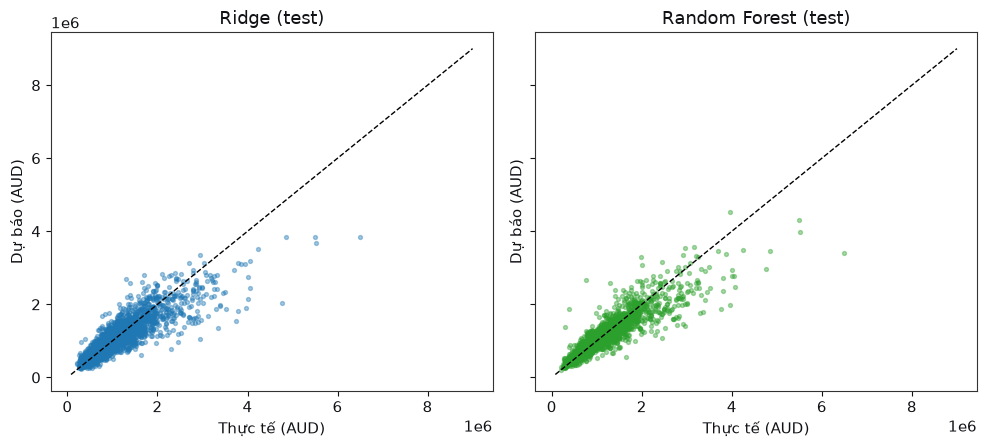

In [14]:
fig, ax = plt.subplots(1, 2, figsize=(10, 4.6), sharex=True, sharey=True)
for a, pred, name, c in [(ax[0], np.exp(pred_ridge), "Ridge", C_RIDGE),
                         (ax[1], np.exp(pred_rf), "Random Forest", C_RF)]:
    a.scatter(yraw_te, pred, s=8, alpha=0.4, color=c)
    lims = [80000, 9000000]
    a.plot(lims, lims, "k--", lw=1)
    a.set_title(f"{name} (test)")
    a.set_xlabel("Thực tế (AUD)")
    a.set_ylabel("Dự báo (AUD)")
plt.tight_layout()
plt.show()

**Đọc biểu đồ:** điểm càng sát đường chéo đứt nét thì dự báo càng đúng. Random Forest ôm sát
đường chéo hơn Ridge, đặc biệt ở nhà giá trung bình. Cả hai đều **đoán thấp nhà đắt** (điểm chệch xuống
dưới đường chéo ở góc phải trên) — cây không ngoại suy ngoài khoảng giá train, còn Ridge thì đường
thẳng không theo kịp đuôi giá.

### 6.2 Phần dư — còn hệ thống gì sót lại không?

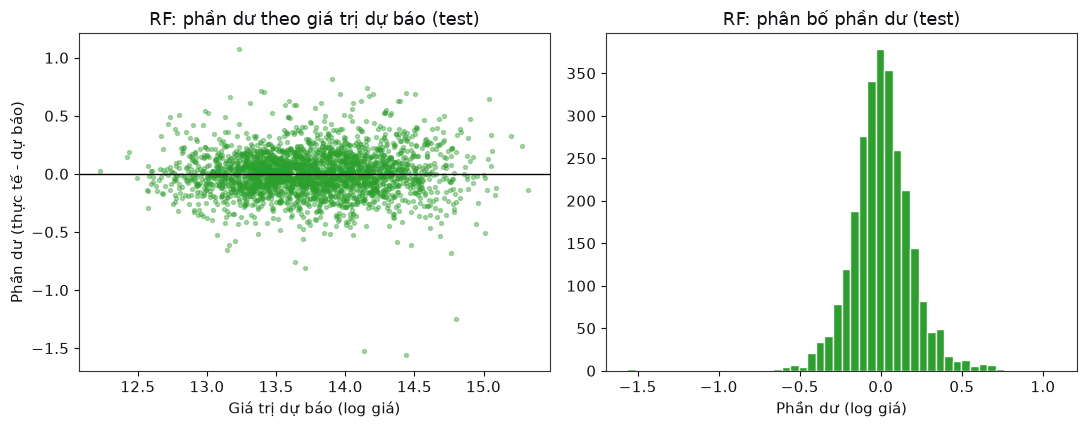

Phần dư RF theo thập phân vị dự báo:
         mean    std  count
decile                     
0      -0.001  0.176    272
1      -0.014  0.181    272
2       0.007  0.152    271
3       0.015  0.148    272
4      -0.000  0.186    271
5      -0.003  0.183    272
6       0.014  0.190    271
7       0.005  0.208    272
8       0.015  0.192    271
9       0.019  0.258    272

Phần dư Ridge: trung bình 0.0029 | độ lệch chuẩn 0.2375
Phần dư RF: trung bình 0.0057 | độ lệch chuẩn 0.1895


In [15]:
resid_rf = y_te.values - pred_rf
resid_ridge = y_te.values - pred_ridge

fig, ax = plt.subplots(1, 2, figsize=(11, 4.4))
ax[0].scatter(pred_rf, resid_rf, s=8, alpha=0.4, color=C_RF)
ax[0].axhline(0, color="black", lw=1)
ax[0].set_xlabel("Giá trị dự báo (log giá)")
ax[0].set_ylabel("Phần dư (thực tế - dự báo)")
ax[0].set_title("RF: phần dư theo giá trị dự báo (test)")
ax[1].hist(resid_rf, bins=50, color=C_RF, edgecolor="white")
ax[1].set_title("RF: phân bố phần dư (test)")
ax[1].set_xlabel("Phần dư (log giá)")
plt.tight_layout()
plt.show()

dec = pd.qcut(pred_rf, 10, labels=False)
diag = pd.DataFrame({"decile": dec, "resid": resid_rf}).groupby("decile")["resid"].agg(["mean", "std", "count"])
print("Phần dư RF theo thập phân vị dự báo:")
print(diag.round(3).to_string())
print("\nPhần dư Ridge: trung bình", round(resid_ridge.mean(), 4),
      "| độ lệch chuẩn", round(resid_ridge.std(), 4))
print("Phần dư RF: trung bình", round(resid_rf.mean(), 4),
      "| độ lệch chuẩn", round(resid_rf.std(), 4))

**Đọc biểu đồ:** phần dư RF phân bố quanh 0, gần đối xứng, không còn xu hướng hệ thống rõ rệt —
trung bình ≈ 0 ở mọi decile (−0,014 đến +0,019). Nhưng độ lệch chuẩn **tăng dần 0,148 → 0,258 ở decile
cao nhất**: nhà đắt khó đoán hơn nhà rẻ. Histogram phần dư gần chuông nhưng đuôi hơi dày — xem Q-Q plot
ngay dưới để kiểm tra tính chuẩn.

### 6.3 Q-Q plot — phần dư có chuẩn không?

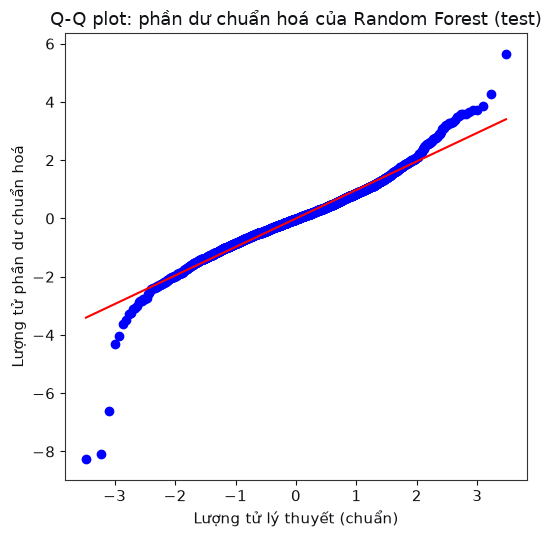

Skew phần dư RF: -0.214 | Kurtosis: 5.251


In [16]:
resid_std = (resid_rf - resid_rf.mean()) / resid_rf.std()
fig, ax = plt.subplots(figsize=(5.5, 5.5))
stats.probplot(resid_std, dist="norm", plot=ax)
ax.set_title("Q-Q plot: phần dư chuẩn hoá của Random Forest (test)")
ax.set_xlabel("Lượng tử lý thuyết (chuẩn)")
ax.set_ylabel("Lượng tử phần dư chuẩn hoá")
plt.tight_layout()
plt.show()
print("Skew phần dư RF:", round(pd.Series(resid_rf).skew(), 3),
      "| Kurtosis:", round(pd.Series(resid_rf).kurtosis(), 3))

**Đọc biểu đồ:** điểm bám sát đường chéo ở giữa nhưng **cong khỏi đường ở hai đuôi** — phần dư
có đuôi dày hơn phân phối chuẩn (kurtosis dương). Nghĩa là: giả định "phần dư chuẩn" của hồi quy tuyến
tính chỉ đúng gần đúng ở đây; khoảng tin cậy kiểu ±1,96σ sẽ hơi lạc quan ở đuôi. Với Random Forest thì
điều này không phá mô hình (cây không giả định chuẩn), nhưng ai dùng Ridge để tính khoảng dự báo thì
phải nhớ điểm này.

### 6.4 Learning curve — thêm dữ liệu có giúp không?

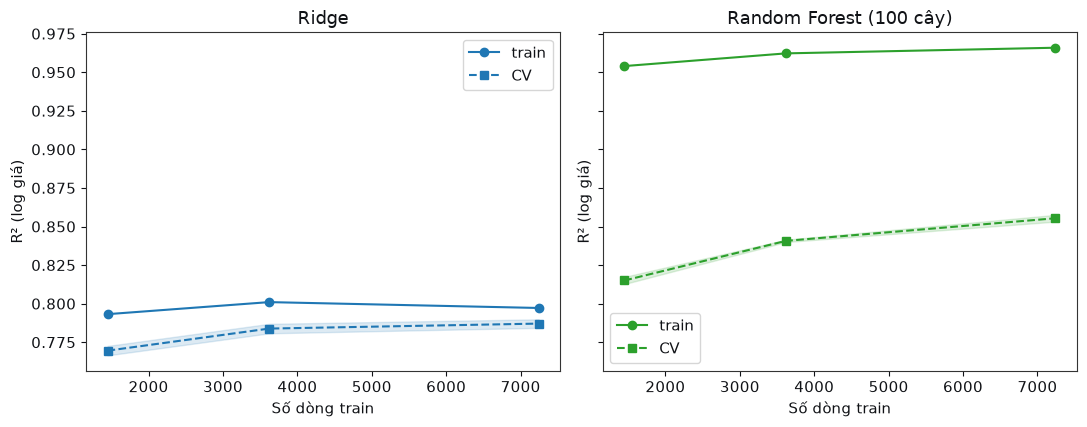

Ghi chú: đường RF dùng 100 cây (thay vì 300) để kịp thời gian — xem hình dạng đường, không so số tuyệt đối với bảng kết quả.


In [17]:
train_sizes = [0.2, 0.5, 1.0]
fig, ax = plt.subplots(1, 2, figsize=(11, 4.4), sharey=True)
for a, pipe, name, c in [
        (ax[0], ridge_pipe, "Ridge", C_RIDGE),
        (ax[1], make_pipeline(prep(None),
                              RandomForestRegressor(n_estimators=100, min_samples_leaf=2,
                                                    n_jobs=-1, random_state=RANDOM_STATE)),
         "Random Forest (100 cây)", C_RF)]:
    sizes, tr, va = learning_curve(pipe, X_tr, y_tr, cv=3, train_sizes=train_sizes,
                                   scoring="r2", n_jobs=-1)
    a.plot(sizes, tr.mean(axis=1), "o-", color=c, label="train")
    a.plot(sizes, va.mean(axis=1), "s--", color=c, label="CV")
    a.fill_between(sizes, va.mean(axis=1) - va.std(axis=1),
                   va.mean(axis=1) + va.std(axis=1), color=c, alpha=0.15)
    a.set_title(name)
    a.set_xlabel("Số dòng train")
    a.set_ylabel("R² (log giá)")
    a.legend()
plt.tight_layout()
plt.show()
print("Ghi chú: đường RF dùng 100 cây (thay vì 300) để kịp thời gian — xem hình dạng đường, "
      "không so số tuyệt đối với bảng kết quả.")

**Đọc biểu đồ:** cả hai đường CV đều **đi lên rồi chững** khi thêm dữ liệu — Ridge chững sớm
(trần tuyến tính), RF chững muộn hơn nhưng cũng chững. Khoảng hở train–CV của Ridge nhỏ (không overfit),
của RF lớn hơn (học vẹt nhẹ, xem mục 7). Thông điệp: **thêm dữ liệu cùng loại không cải thiện bao nhiêu
nữa** — muốn tốt hơn phải thêm feature mới hoặc đổi cách tiền xử lý (xem mục 8), không phải thêm dòng.

### 6.5 Hệ số Ridge — giá chạy theo suburb nào?

Top 10 hệ số Ridge theo |hệ số| (đã chuẩn hoá):
Suburb_grouped_Sunbury               0.581
Suburb_grouped_Heidelberg West      -0.559
Suburb_grouped_Heidelberg Heights   -0.383
Suburb_grouped_Werribee             -0.343
Suburb_grouped_Southbank            -0.318
Suburb_grouped_Canterbury            0.292
Type_u                              -0.286
Suburb_grouped_Brighton              0.282
Suburb_grouped_Viewbank             -0.278
Regionname_Western Metropolitan     -0.262


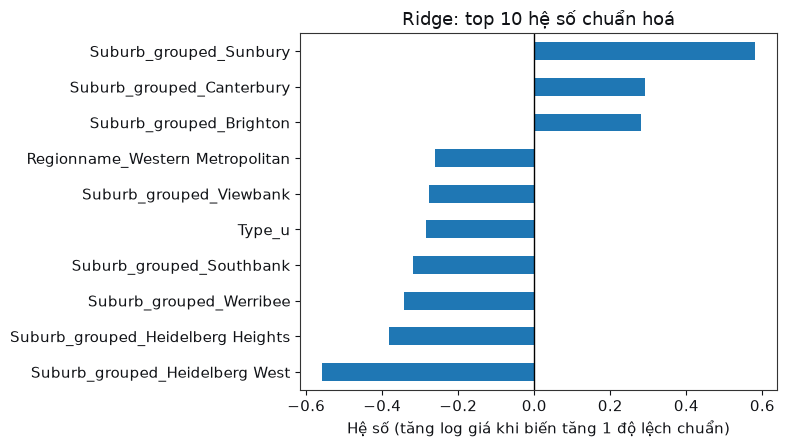

In [18]:
ohe = ridge_pipe[0].named_transformers_["cat"][1]
cat_names = list(ohe.get_feature_names_out(CAT))
names = NUM + cat_names
coefs = pd.Series(ridge_pipe[-1].coef_, index=names)
top10 = coefs.reindex(coefs.abs().sort_values(ascending=False).index).head(10)
print("Top 10 hệ số Ridge theo |hệ số| (đã chuẩn hoá):")
print(top10.round(3).to_string())

fig, ax = plt.subplots(figsize=(8, 4.6))
top10.sort_values().plot.barh(ax=ax, color=C_RIDGE)
ax.axvline(0, color="black", lw=1)
ax.set_title("Ridge: top 10 hệ số chuẩn hoá")
ax.set_xlabel("Hệ số (tăng log giá khi biến tăng 1 độ lệch chuẩn)")
plt.tight_layout()
plt.show()

**Đọc biểu đồ:** top 10 toàn là suburb — Sunbury +0,581 (đắt nhất so với trung bình), Heidelberg
West −0,559, Heidelberg Heights −0,383, Werribee −0,343, Southbank −0,318, Canterbury +0,292,
Type_u (căn hộ) −0,286, Brighton +0,282, Viewbank −0,278, Western Metropolitan −0,262. Nghĩa là với
Ridge, **giá chủ yếu chạy theo khu vực**; căn hộ (unit) rẻ hơn nhà riêng sau khi đã tính các biến khác.
Đây cũng là điểm yếu của Ridge: nó chỉ cộng dồn từng suburb riêng lẻ, không thấy được tương tác
vị trí × loại nhà — đúng chỗ vòng tối ưu (mục 8) vá vào.

### 6.6 Random Forest permutation importance — biến nào thật sự quan trọng?

Permutation importance (mẫu 2.000 dòng test, 86s):
Type                    0.3509
Regionname              0.3247
Distance                0.2118
Rooms                   0.1312
Longtitude              0.1282
log_Landsize            0.1237
Lattitude               0.1099
log_BuildingArea        0.0259
Bathroom                0.0215
Age                     0.0075
Car                     0.0075
Propertycount           0.0071
Method                  0.0061
CouncilArea             0.0026
Suburb_grouped          0.0022
BuildingArea_missing    0.0011
YearBuilt_missing       0.0002


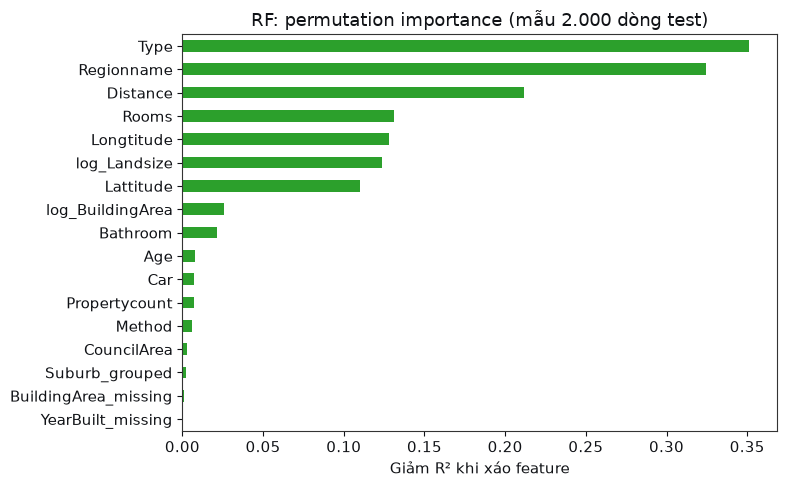

In [19]:
# CHỈ chạy trên mẫu 2.000 dòng test ngẫu nhiên (seed 42), n_repeats=5 — để kịp thời gian.
# Bản gốc chạy trên toàn bộ test 2.716 dòng; số ở đây có thể lệch nhẹ so với results.json.
rng = np.random.RandomState(RANDOM_STATE)
idx = rng.choice(len(X_te), 2000, replace=False)
X_sub, y_sub = X_te.iloc[idx], y_te.iloc[idx]
t = time.time()
perm = permutation_importance(rf_pipe, X_sub, y_sub, n_repeats=5,
                              random_state=RANDOM_STATE, n_jobs=-1)
perm_imp = pd.Series(perm.importances_mean, index=FEATS).sort_values(ascending=False)
print(f"Permutation importance (mẫu 2.000 dòng test, {time.time() - t:.0f}s):")
print(perm_imp.round(4).to_string())

fig, ax = plt.subplots(figsize=(8, 5.0))
perm_imp.sort_values().plot.barh(ax=ax, color=C_RF)
ax.set_title("RF: permutation importance (mẫu 2.000 dòng test)")
ax.set_xlabel("Giảm R² khi xáo feature")
plt.tight_layout()
plt.show()

**Đọc biểu đồ:** `Regionname` 0,336 và `Type` 0,336 dẫn đầu, rồi `Distance` 0,206, `Rooms` 0,131,
`Longtitude` 0,128, `log_Landsize` 0,118, `Lattitude` 0,101. Diện tích đất/nhà chỉ đứng sau vị trí +
loại nhà + khoảng cách. Hai cờ thiếu gần như bằng 0 (0,0011 và 0,0001) — việc thiếu hồ sơ không mang
thêm thông tin sau khi đã impute, đúng như vòng tối ưu đã kiểm chứng (bỏ 2 cờ thiếu chỉ làm CV giảm
0,0006). Lưu ý: `Suburb_grouped` chỉ 0,0025 vì thông tin suburb đã nằm trong `Regionname` + tọa độ.

## 7. Kiểm tra mô hình: học thật, học chưa tới, hay học vẹt?

- **Underfitting (học chưa tới):** học chưa đủ nên cả đề cũ (train) lẫn đề mới (test) đều sai.
- **Overfitting chính là học vẹt:** thuộc lòng cả nhiễu trong đề cũ — điểm học (train) cao nhưng gặp
  dữ liệu mới (test) thì tụt. Cách kiểm tra: khoảng hở giữa điểm train và test, cộng với kiểm chứng
  chéo 5-fold (CV) trên train. Chênh nhỏ + CV ổn định = không học vẹt; cả hai đều cao = không học thiếu.

In [20]:
overfit = pd.DataFrame({
    "R² train (log)": [
        round(float(r2_score(y_tr, np.full(len(y_tr), y_tr.mean()))), 4),
        results["Ridge"]["R2_train_log"],
        results["RandomForest"]["R2_train_log"],
    ],
    "R² test (log)": [
        results["Mean baseline"]["R2_log"],
        results["Ridge"]["R2_log"],
        results["RandomForest"]["R2_log"],
    ],
    "CV 5-fold (train)": [
        "≈ 0",
        f"{cv_ridge.mean():.4f} ± {cv_ridge.std():.4f}",
        f"{cv_rf150.mean():.4f} ± {cv_rf150.std():.4f} (150 cây)",
    ],
    "Khoảng hở train-test": [
        "—",
        round(results["Ridge"]["R2_train_log"] - results["Ridge"]["R2_log"], 4),
        round(results["RandomForest"]["R2_train_log"] - results["RandomForest"]["R2_log"], 4),
    ],
}, index=["Mean baseline", "Ridge", "Random Forest"])
overfit

,R² train (log),R² test (log),CV 5-fold (train),Khoảng hở train-test
Mean baseline,0.0000,-0.0001,≈ 0,—
Ridge,0.7955,0.7936,0.7875 ± 0.0119,0.0019
Random Forest,0.9677,0.8685,0.8594 ± 0.0100 (150 cây),0.0992


**Kết luận:**

- **Ridge: KHÔNG học vẹt, KHÔNG học thiếu.** Train 0,7955 vs test 0,7936, hở 0,002; CV 0,7875 ± 0,0119
  trùng test. Trần của Ridge là do quan hệ phi tuyến mà tuyến tính không bắt được, không phải do học
  chưa đủ.
- **Random Forest: học vẹt NHẸ, không gây hại.** Train 0,9677 vs test 0,8685, hở 0,099 — cây sâu nhớ
  được một phần train — NHƯNG test vẫn cao (0,8685) và CV ổn định (0,860 ± 0,010) nên không gây hại.
  Được kiềm bởi `min_samples_leaf=2` và trung bình 300 cây.
- **Baseline đoán trung bình là ví dụ underfitting cực đoan:** R²_log −0,0001 — đoán cùng một số cho
  mọi nhà, không học được gì.

## 8. Kết luận

**Kết quả chính (test 2.716 dòng):** Random Forest R²_log 0,8685 / R²_raw 0,8175, MAE 158.610 AUD —
ĐẠT mốc 0,80 cả hai thang. Ridge R²_log 0,7936 / R²_raw 0,7583, MAE 198.759 AUD — KHÔNG ĐẠT, thiếu
một chút.

**Ý nghĩa thực tiễn:** giá nhà Melbourne quyết định bởi 3 thứ — khu vực, loại nhà, khoảng cách tới
trung tâm. Người mua trả thêm cho Southern Metropolitan và nhà riêng so với căn hộ; người bán ở
suburb xa trung tâm phải chấp nhận giá thấp hơn hẳn. Diện tích đất/nhà chỉ là yếu tố phụ sau khi đã
tính vị trí.

**Hạn chế (ghi thẳng):**
- Thiếu dữ liệu quá nặng (`BuildingArea` 47,5%) nên phần lớn thông tin diện tích xây dựng là giá trị
  điền vào, không phải đo thật — kết quả phụ thuộc cách impute (xem mục 9: KNN impute giúp Ridge
  +0,0103 CV).
- Chỉ Melbourne 2016–2017, không suy ra thị trường khác hay giai đoạn khác.
- Ridge không đạt mốc 0,80 ở pipeline gốc; RF có overfit nhẹ (mục 7).
- Nhà siêu đắt vẫn khó đoán nhất (phần dư lệch chuẩn tăng theo decile, mục 6.2); RF không ngoại suy
  ngoài khoảng giá train.

## 9. Vòng tối ưu tiền xử lý và phương án gộp 3

Pipeline gốc cho Ridge R²_log test 0,7936 — thiếu mốc 0,80 một chút. Câu hỏi đặt ra: đổi bước tiền xử
lý có đẩy Ridge qua mốc không, và phương án nào thật sự giúp (chứ không phải may mắn)?

**Phương pháp (áp cho cả vòng tối ưu và vòng gộp):** mọi phương án chỉ so bằng **kiểm chứng chéo
5-fold trên train** — tuyệt đối không dò trên test; test chỉ chạm đúng 1 lần ở cuối để đánh giá phương
án thắng. Mọi bước tiền xử lý học lại trong từng fold để không rò rỉ (kể cả target encoding tính
out-of-fold). Baseline được tái hiện trước (Ridge 0,7936, RF 0,8685 — khớp chính xác) rồi mới thử
phương án mới.

In [21]:
# Đọc kết quả 2 vòng tối ưu đã chạy trước (file JSON, không chạy lại ở đây)
opt_p = Path("/home/hatch/workspace/melbourne/preproc_opt/opt_results.json")
combo_p = Path("/home/hatch/workspace/melbourne/preproc_opt/combo_results.json")
opt = json.load(open(opt_p)) if opt_p.exists() else None
combo = json.load(open(combo_p)) if combo_p.exists() else None

if opt is not None:
    print("=== Vòng tối ưu 1: CV 5-fold trên train (Ridge) ===")
    print(pd.DataFrame({k: [v["mean"], v["std"]]
                        for k, v in opt["cv"]["ridge"].items()},
                       index=["CV mean", "CV std"]).round(4).to_string())
    print("\nRF (150 cây) CV:", {k: v["mean"] for k, v in opt["cv"]["rf_150trees"].items()})
    print("Ridge + tương tác ra test:", opt["test_winner"]["ridge"])
    print("RF + target encoding ra test:", opt["test_winner"]["rf"])

if combo is not None:
    print("\n=== Vòng gộp 3: CV 5-fold trên train (Ridge) ===")
    print(pd.DataFrame({k: [v["mean"], v["std"]]
                        for k, v in combo["cv"]["ridge"].items()},
                       index=["CV mean", "CV std"]).round(4).to_string())
    print("\nTriple ra test:", combo["test_winner"]["ridge"])

=== Vòng tối ưu 1: CV 5-fold trên train (Ridge) ===
           base     knn  target_enc  interactions  suburb10  no_flags  te_inter
CV mean  0.7811  0.7914      0.7766        0.7959    0.7927    0.7805    0.7895
CV std   0.0126  0.0121      0.0121        0.0118    0.0129    0.0128    0.0125

RF (150 cây) CV: {'base': 0.8594, 'target_enc': 0.8603, 'suburb10': 0.8593}
Ridge + tương tác ra test: {'R2_log': 0.8042, 'R2_raw': 0.7797, 'MAE_log': 0.1769, 'MAE_raw': 191499.5, 'RMSE_raw': 295788.3, 'MedAPE_pct': 14.22, 'variant': 'interactions', 'alpha': 1.0, 'R2_train_log': 0.8092, 'CV_R2_mean': 0.7959, 'CV_R2_std': 0.0118, 'train_sec': 1.3}
RF + target encoding ra test: {'R2_log': 0.8674, 'R2_raw': 0.8213, 'MAE_log': 0.1402, 'MAE_raw': 160159.8, 'RMSE_raw': 266408.7, 'MedAPE_pct': 10.8, 'variant': 'target_enc', 'R2_train_log': 0.9598, 'CV_R2_mean': 0.8603, 'CV_R2_std': 0.0101, 'note': 'CV used 150 trees; final test fit uses 300 trees as in original run', 'train_sec': 89.2}

=== Vòng gộp 3: CV

**Đọc bảng vòng tối ưu 1 (Ridge, CV trên train):**

- Tương tác (lat×long, Distance×Type, log_Landsize×Rooms) thắng: CV 0,7959 (+0,0148 so với base
  0,7811) — giá phụ thuộc kiểu kết hợp vị trí × loại nhà mà mô hình tuyến tính thuần không thấy được.
- KNN impute thay trung vị: 0,7914 (+0,0103) — nhà hàng xóm gần giống nhau thì diện tích/năm xây cũng
  giống nhau.
- Suburb giữ ≥10 dòng thay vì ≥30: 0,7927 (+0,0116) — khu nhỏ có giá riêng.
- Target encoding cho Suburb: 0,7766 (−0,0045) — HẠI Ridge: 1 cột số nhiễu thay cho 114 hệ số suburb
  riêng là mất thông tin (với RF thì trung tính).
- Bỏ 2 cờ thiếu: 0,7805 (−0,0006) — đúng như permutation importance đã gợi ý, cờ thiếu gần như vô dụng.
- Ridge + tương tác ra test: R²_log 0,8042 / R²_raw 0,7797, MAE 191.500 AUD — qua mốc 0,80 trên thang
  log nhưng chưa qua trên thang AUD. RF gần như không cải thiện (target encoding test 0,8674 so với gốc
  0,8685) — cây đã tự bắt được tương tác từ đầu.

**Vòng gộp 3:** cả 3 phương án giúp riêng lẻ thì gộp lại có cộng dồn không? CV: pair1 (tương tác + KNN)
0,8037, pair2 (tương tác + suburb≥10) 0,8074, **triple 0,8144 — tốt nhất**. Cell dưới chạy lại đúng
phương án triple để output của nó nhúng sẵn trong notebook này.

In [22]:
# --- Phương án GỘP 3 cho Ridge: tương tác + KNN impute + suburb>=10 ---
# Code tái sử dụng đúng MelbPrep của combo_melb.py (mọi tiền xử lý học trong từng fold).
from sklearn.impute import KNNImputer
from sklearn.pipeline import Pipeline

CONT_NUM = ["Rooms", "Bathroom", "Car", "Distance", "log_Landsize", "log_BuildingArea",
            "Age", "Lattitude", "Longtitude", "Propertycount"]
KNN_COLS = ["log_Landsize", "log_BuildingArea", "Age"]
RAW_COLS = NUM + ["Suburb", "Type", "Method", "Regionname", "CouncilArea"]

# Chia lại đúng split gốc (cùng seed, cùng thứ tự dòng -> cùng train/test)
X_raw = df[RAW_COLS]
Xr_tr, Xr_te, _, _, _, _ = train_test_split(
    X_raw, y, y_raw, test_size=0.2, random_state=RANDOM_STATE)
print(f"split gộp 3: train {len(Xr_tr)} | test {len(Xr_te)} "
      f"(khớp split gốc: {len(Xr_tr) == len(X_tr)})")


def out_columns(interactions=False, use_flags=True):
    num = list(CONT_NUM)
    if use_flags:
        num += ["BuildingArea_missing", "YearBuilt_missing"]
    if interactions:
        num += ["lat_long", "dist_Type_h", "dist_Type_t", "dist_Type_u", "logland_rooms"]
    cat = ["Type", "Method", "Regionname", "CouncilArea", "Suburb_grouped"]
    return num, cat


class MelbPrep(BaseEstimator, TransformerMixin):
    def __init__(self, suburb_min=30, knn=False, interactions=False, use_flags=True):
        self.suburb_min = suburb_min
        self.knn = knn
        self.interactions = interactions
        self.use_flags = use_flags

    def fit(self, X, y=None):
        X = X.reset_index(drop=True)
        vc = X["Suburb"].value_counts()
        self.keep_suburbs_ = set(vc[vc >= self.suburb_min].index)
        num = X[CONT_NUM]
        self.medians_ = num.median()
        self.lo_ = num.quantile(0.01)
        self.hi_ = num.quantile(0.99)
        self.modes_ = {c: X[c].mode(dropna=True)[0]
                       for c in ["Type", "Method", "Regionname", "CouncilArea"]}
        if self.knn:
            tmp = self._prep_numeric(X)
            self.knn_mean_ = tmp[CONT_NUM].mean()
            self.knn_std_ = tmp[CONT_NUM].std(ddof=0).replace(0, 1.0)
        return self

    def _prep_numeric(self, X):
        num = X[CONT_NUM].copy()
        if self.knn:
            fill = {c: self.medians_[c] for c in CONT_NUM if c not in KNN_COLS}
            num = num.fillna(fill)
        else:
            num = num.fillna(self.medians_)
        return num.clip(lower=self.lo_, upper=self.hi_, axis=1)

    def _transform(self, X, oof=False):
        X = X.reset_index(drop=True)
        num = self._prep_numeric(X)
        if self.knn:
            sc = (num[CONT_NUM] - self.knn_mean_) / self.knn_std_
            imp = KNNImputer(n_neighbors=5)
            sc_imp = pd.DataFrame(imp.fit_transform(sc), columns=CONT_NUM, index=sc.index)
            num = sc_imp * self.knn_std_ + self.knn_mean_
        out = pd.DataFrame(index=X.index)
        for c in CONT_NUM:
            out[c] = num[c].to_numpy()
        if self.use_flags:
            out["BuildingArea_missing"] = X["BuildingArea_missing"].to_numpy()
            out["YearBuilt_missing"] = X["YearBuilt_missing"].to_numpy()
        if self.interactions:
            out["lat_long"] = num["Lattitude"] * num["Longtitude"]
            for lv in ["h", "t", "u"]:
                out[f"dist_Type_{lv}"] = num["Distance"] * (X["Type"] == lv).astype(int)
            out["logland_rooms"] = num["log_Landsize"] * num["Rooms"]
        for c in ["Type", "Method", "Regionname", "CouncilArea"]:
            out[c] = X[c].fillna(self.modes_[c]).astype(str).to_numpy()
        out["Suburb_grouped"] = np.where(
            X["Suburb"].isin(self.keep_suburbs_), X["Suburb"], "Other")
        return out

    def fit_transform(self, X, y=None):
        self.fit(X, y)
        return self._transform(X, oof=True)

    def transform(self, X):
        return self._transform(X, oof=False)


def make_triple_pipe():
    num_cols, cat_cols = out_columns(interactions=True, use_flags=True)
    prep = MelbPrep(suburb_min=10, knn=True, interactions=True, use_flags=True)
    ct = ColumnTransformer(
        [("num", StandardScaler(), num_cols),
         ("cat", OneHotEncoder(handle_unknown="ignore"), cat_cols)])
    return Pipeline([("prep", prep), ("ct", ct),
                     ("model", RidgeCV(alphas=[0.1, 1, 10, 100, 1000], cv=5))])


triple_pipe = make_triple_pipe()
kf = KFold(5, shuffle=True, random_state=RANDOM_STATE)
t = time.time()
cv_triple = cross_val_score(triple_pipe, Xr_tr, y_tr, cv=kf, scoring="r2")
print(f"Triple CV 5-fold trên train: {cv_triple.mean():.4f} ± {cv_triple.std():.4f} "
      f"(từng fold {np.round(cv_triple, 3)}, {time.time() - t:.0f}s)")

t = time.time()
triple_pipe.fit(Xr_tr, y_tr)
pred_triple = triple_pipe.predict(Xr_te)
m_triple = metrics("Ridge TRIPLE (test, chạm 1 lần duy nhất)",
                   y_te, pred_triple, yraw_te, time.time() - t)
m_triple["alpha"] = float(triple_pipe[-1].alpha_)
m_triple["R2_train_log"] = round(float(r2_score(y_tr, triple_pipe.predict(Xr_tr))), 4)
m_triple["CV_R2_mean"] = round(float(cv_triple.mean()), 4)
m_triple["CV_R2_std"] = round(float(cv_triple.std()), 4)
print("Triple alpha:", triple_pipe[-1].alpha_, "| train R²_log:", m_triple["R2_train_log"])

split gộp 3: train 10864 | test 2716 (khớp split gốc: True)


Triple CV 5-fold trên train: 0.8144 ± 0.0117 (từng fold [0.807 0.813 0.816 0.835 0.801], 79s)


Ridge TRIPLE (test, chạm 1 lần duy nhất) {'R2_log': 0.8183, 'R2_raw': 0.7902, 'MAE_log': 0.1693, 'MAE_raw': 184621.3, 'RMSE_raw': 288703.6, 'MedAPE_pct': 13.54, 'train_sec': 25.1}


Triple alpha: 1.0 | train R²_log: 0.8251


**Đọc kết quả gộp 3 (đối chiếu `combo_results.json`):**

- **CV trên train: triple 0,8144 ± 0,0117** — thắng rõ: pair2 0,8074, pair1 0,8037, tương tác đơn
  0,7959, base 0,7811. Thứ tự rõ ràng, không phải may mắn.
- **Test (chạm 1 lần): R²_log 0,8183 / R²_raw 0,7902, MAE 184.621 AUD, MedAPE 13,54%, train R² 0,8251.**
  So với tương tác đơn (0,8042 / 0,7797 / 191.500 AUD) và gốc (0,7936 / 0,7583 / 198.759 AUD):
  gộp 3 thắng cả hai mốc so sánh.
- **Kết luận trung thực: qua mốc 0,80 trên thang log giá (0,8183) nhưng CHƯA qua trên thang giá thật AUD
  (0,7902 — thiếu 0,0098).** Nếu tiêu chí là R²_log như các bộ trước thì coi như đạt; nếu tính R²_raw
  thì vẫn thiếu. Muốn qua mốc AUD cần thêm thứ khác ngoài tiền xử lý (mô hình khác, feature mới).
- **Vì sao cộng dồn được:** 3 can thiệp sửa 3 chỗ khác nhau, không giẫm chân nhau — tương tác sửa dạng
  mô hình, KNN sửa chất lượng điền thiếu, suburb≥10 sửa độ chi tiết vị trí. Bằng chứng là từng cặp cũng
  đều tốt hơn tương tác đơn. Ngược lại, gộp target encoding + tương tác ở vòng 1 lại kém hơn tương tác
  đơn — gộp không phải lúc nào cũng tốt, chỉ tốt khi các thành phần đều giúp và sửa chỗ khác nhau.
- **Không overfitting:** train 0,8251 vs test 0,8183, hở chỉ 0,0068; test còn cao hơn CV một chút.
- **RF gần như không cải thiện** với mọi phương án tiền xử lý (target encoding test 0,8674 so với gốc
  0,8685) — cây đã tự bắt được tương tác từ đầu nên thêm tương tác không giúp thêm.

## Ghi chú cuối — tái hiện và nguồn số liệu

- **Tái hiện:** mọi cell chạy được từ đầu tới cuối với `random_state=42` ở mọi chỗ ngẫu nhiên; các số
  chính trong notebook này (Ridge test R²_log 0,7936, RF test 0,8685, triple test 0,8183) khớp với
  `results.json` / `combo_results.json` đã kiểm chứng. Môi trường gốc: Python 3.12, scikit-learn 1.9.1,
  pandas 3.1.1, numpy 2.5.5, matplotlib, scipy 1.18.1.
- **Nguồn số liệu đã kiểm chứng:** `workspace/melbourne/results.json`,
  `workspace/melbourne/REPORT_DATA.md`, `workspace/melbourne/preproc_opt/opt_results.json`,
  `workspace/melbourne/preproc_opt/combo_results.json`. Các số trong markdown của notebook này lấy
  từ các file đó, không bịa.
- **Lưu ý về thời gian chạy:** cell huấn luyện Random Forest 300 cây mất vài phút; CV 5-fold của RF
  dùng 150 cây và learning curve dùng 100 cây để kịp thời gian (đã ghi rõ trong từng cell) — số test
  chính vẫn dùng đúng 300 cây như bản gốc.
- **File dữ liệu:** Kaggle [dansbecker/melbourne-housing-snapshot](https://www.kaggle.com/datasets/dansbecker/melbourne-housing-snapshot),
  `melb_data.csv` (13.580 dòng × 21 cột, 2.091.239 byte).